# Lab: Ángulo y similitud coseno

**Meta:** calcular ángulos y similitudes coseno con NumPy, buscar el usuario de MovieLens más
parecido a otro y comprobar que la similitud coseno y la distancia no siempre escogen al mismo.
Acompaña a la página de conceptos
[Ángulo, similitud coseno y las desigualdades de Cauchy-Schwarz y triangular](l03_concept_angulo_coseno.qmd).

> **Cómo usar este laboratorio:** en el sitio del curso esta página es de solo lectura: muestra
> el código junto con lo que produjo. Para ejecutarlo, ábrelo en Google Colab y usa *Archivo,
> Guardar una copia en Drive* antes de trabajar. Ejecuta las celdas en orden, de arriba abajo.

## Preparación

Este laboratorio no instala nada: Colab ya trae NumPy, pandas y Matplotlib. La celda de
preparación importa las bibliotecas, fija la semilla y carga los datos: calificaciones de
películas de MovieLens, un servicio que recomienda películas. El archivo del curso es una parte
del conjunto *ml-latest-small* de GroupLens (licencia y cita junto al archivo, en
`movielens_top20.provenance.txt`): las 20 películas con más calificaciones y los 413 usuarios que
calificaron al menos 5 de ellas. Ejecútala cada vez que abras el laboratorio.

In [1]:
# Preparacion: bibliotecas, semilla y datos. Seguro de ejecutar de nuevo.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(4031)

# Calificaciones de MovieLens (GroupLens, ml-latest-small; Harper y Konstan, 2015), copia
# del curso: una fila por usuario, una columna por pelicula, 0 = no la califico.
RUTA = Path("data/movielens_top20.csv")
URL = "https://raw.githubusercontent.com/devomh/mate4031-2027/main/u01_vectores/data/movielens_top20.csv"
calificaciones = pd.read_csv(RUTA if RUTA.exists() else URL, index_col=0)
R = calificaciones.to_numpy()

print("matriz R:", R.shape)
print("primera pelicula:", calificaciones.columns[0])

matriz R: (413, 20)
primera pelicula: Forrest Gump (1994)


<details><summary>Resultado esperado</summary>

~~~text
matriz R: (413, 20)
primera pelicula: Forrest Gump (1994)
~~~
</details>

`R` es una matriz de datos (L01): 413 usuarios por 20 películas. Cada fila es un usuario, un
vector de $\mathbb{R}^{20}$ con sus estrellas, de 0.5 a 5; un 0 quiere decir que no calificó esa
película. `index_col=0` toma la primera columna del archivo, el número de usuario, como el
índice de la tabla: `calificaciones.loc[308]` es la fila del usuario 308. Los títulos de las
películas son las columnas, `calificaciones.columns`; la primera es `calificaciones.columns[0]`.

## Paso 1: el ángulo entre dos vectores

El ángulo (*angle*) $\theta$ entre $\mathbf{u}$ y $\mathbf{v}$ cumple
$\cos\theta = \mathbf{u} \cdot \mathbf{v} / (\|\mathbf{u}\|\,\|\mathbf{v}\|)$. `np.arccos`
devuelve el ángulo cuyo coseno se le da, **en radianes**; `np.degrees` lo pasa a grados.

In [2]:
def angulo(u, v):
    """El angulo entre u y v, en grados."""
    coseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return np.degrees(np.arccos(coseno))


u = np.array([3, 4])
v = np.array([2, -1])
coseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
print("coseno:", round(coseno, 4))
print("en radianes:", round(np.arccos(coseno), 4))
print("en grados:", round(angulo(u, v), 1))

coseno: 0.1789
en radianes: 1.3909
en grados: 79.7


<details><summary>Resultado esperado</summary>

~~~text
coseno: 0.1789
en radianes: 1.3909
en grados: 79.7
~~~
</details>

Son los números de la página de conceptos: $\cos\theta = 2/(5\sqrt{5}) \approx 0.179$ y
$\theta \approx 79.7^\circ$. El ángulo en radianes, $1.39$, es el mismo ángulo en otra unidad.

El signo del producto punto dice de qué tipo es el ángulo. Completa la línea marcada para
imprimir el producto punto y el ángulo de cada par, quita los `#` y ejecuta.

In [3]:
pares = [([1, 0], [1, 1]), ([2, 1], [-1, 2]), ([1, 2], [-3, 1])]
# for a, b in pares:
#     a, b = np.array(a), np.array(b)
#     print(a, b, "producto punto:", np.dot(a, b), "angulo:", ____)   # <- completa

<details><summary>Resultado esperado</summary>

~~~text
[1 0] [1 1] producto punto: 1 angulo: 45.0
[2 1] [-1  2] producto punto: 0 angulo: 90.0
[1 2] [-3  1] producto punto: -1 angulo: 98.1
~~~
</details>

Producto punto positivo, ángulo agudo; cero, ángulo recto: los vectores son ortogonales
(*orthogonal*); negativo, ángulo obtuso. La línea completa es
`round(angulo(a, b), 1)`.

## Paso 2: textos, coseno y distancia

En la L01 convertiste textos en vectores de conteos. La **similitud coseno** (*cosine
similarity*) de dos vectores es el coseno del ángulo entre ellos. La función `similitud` la
calcula; compárala con la distancia para el primer texto contra los otros dos y contra sí mismo
escrito tres veces. `[d1] * 3` es una lista con `d1` tres veces, y `" ".join(...)` la une en un
solo texto, con un espacio entre las copias.

In [4]:
vocabulario = ["vector", "datos", "matriz", "suma"]
d1 = "una matriz de datos tiene un vector de datos por fila"
d2 = "la suma de un vector y otro vector es un vector"
d3 = "una suma de datos y una matriz"


def conteos(texto):
    palabras = texto.split()
    return np.array([palabras.count(w) for w in vocabulario])


def similitud(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))


x1 = conteos(d1)
for nombre, texto in [("d2", d2), ("d3", d3), ("d1 tres veces", " ".join([d1] * 3))]:
    x = conteos(texto)
    print(nombre, x, "coseno:", round(similitud(x1, x), 3),
          "distancia:", round(np.linalg.norm(x1 - x), 2))

d2 [3 0 0 1] coseno: 0.387 distancia: 3.16
d3 [0 1 1 1] coseno: 0.707 distancia: 1.73
d1 tres veces [3 6 3 0] coseno: 1.0 distancia: 4.9


<details><summary>Resultado esperado</summary>

~~~text
d2 [3 0 0 1] coseno: 0.387 distancia: 3.16
d3 [0 1 1 1] coseno: 0.707 distancia: 1.73
d1 tres veces [3 6 3 0] coseno: 1.0 distancia: 4.9
~~~
</details>

El texto `d1` repetido tres veces dice lo mismo que `d1`, y su vector es $3\mathbf{x}_1$: apunta
en la misma dirección, así que el coseno es exactamente 1. Pero está más lejos de $\mathbf{x}_1$
que los otros dos textos. La distancia ve la longitud y la dirección; el coseno, solo la
dirección.

## Paso 3: el usuario más parecido

Tomemos al usuario 308. Su fila es un vector `r`; los otros 412 usuarios son las filas de
`otros`. La expresión `otros * r` multiplica cada fila por `r`, componente a componente (la
difusión de la L02), y `.sum(axis=1)` suma cada fila: el resultado es el producto punto de
**cada** usuario con `r`. En el `print`, `otros.index[j]` es el número de usuario de la fila
`j`, y `(O[j] > 0) & (r > 0)` marca las películas que calificaron los dos: `&` es "y",
componente a componente, entre dos arreglos de `True` y `False`.

In [5]:
r = calificaciones.loc[308].to_numpy()
otros = calificaciones.drop(308)                 # los demas usuarios
O = otros.to_numpy()

productos = (O * r).sum(axis=1)                  # el producto punto de cada fila con r
cosenos = productos / (np.linalg.norm(O, axis=1) * np.linalg.norm(r))
distancias = np.linalg.norm(O - r, axis=1)

print("el usuario 308 califico", (r > 0).sum(), "peliculas; norma", round(np.linalg.norm(r), 2))
por_coseno = cosenos.argmax()
por_distancia = distancias.argmin()
for nombre, j in [("por coseno", por_coseno), ("por distancia", por_distancia)]:
    print(nombre + ": usuario", otros.index[j], "| califico", (O[j] > 0).sum(),
          "| en comun con 308:", ((O[j] > 0) & (r > 0)).sum())
    print("   coseno", round(cosenos[j], 3), "| distancia", round(distancias[j], 2),
          "| norma", round(np.linalg.norm(O[j]), 2))

el usuario 308 califico 12 peliculas; norma 7.18
por coseno: usuario 246 | califico 10 | en comun con 308: 8
   coseno 0.842 | distancia 8.85 | norma 13.99
por distancia: usuario 10 | califico 6 | en comun con 308: 4
   coseno 0.616 | distancia 5.77 | norma 5.55


<details><summary>Resultado esperado</summary>

~~~text
el usuario 308 califico 12 peliculas; norma 7.18
por coseno: usuario 246 | califico 10 | en comun con 308: 8
   coseno 0.842 | distancia 8.85 | norma 13.99
por distancia: usuario 10 | califico 6 | en comun con 308: 4
   coseno 0.616 | distancia 5.77 | norma 5.55
~~~
</details>

Las dos medidas escogen usuarios distintos. Por coseno, el usuario 246, que calificó 8 de las
películas del 308. Por distancia, el usuario 10: calificó solo 6 películas, 4 en común, y su
vector es el más corto de los 413. El usuario 308 da pocas estrellas, así que su vector también
es corto, y la distancia escoge a otro vector corto.

La figura pone a los 412 usuarios en un plano: la distancia al usuario 308 en el eje horizontal y
la similitud coseno en el vertical. El color es cuántas películas calificó cada uno: `c=vistas`
da a cada punto un color según su número, `cmap` escoge la escala de colores y `fig.colorbar`
dibuja la barra que la explica.

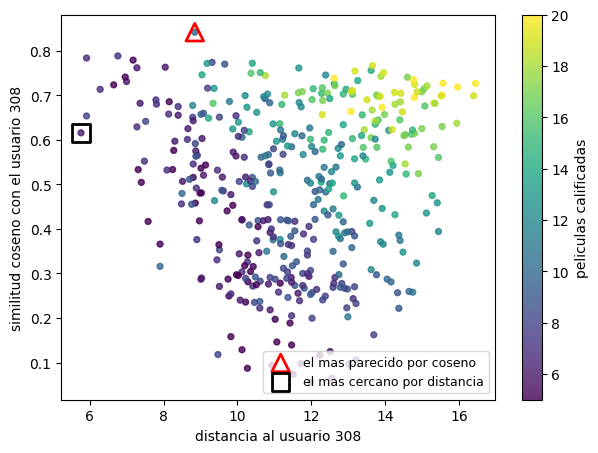

In [6]:
vistas = (O > 0).sum(axis=1)
fig, ax = plt.subplots(figsize=(7, 5))
puntos = ax.scatter(distancias, cosenos, c=vistas, cmap="viridis", s=18, alpha=0.8)
fig.colorbar(puntos, label="peliculas calificadas")
ax.scatter(distancias[por_coseno], cosenos[por_coseno], s=160, marker="^",
           facecolors="none", edgecolors="red", linewidths=2, label="el mas parecido por coseno")
ax.scatter(distancias[por_distancia], cosenos[por_distancia], s=160, marker="s",
           facecolors="none", edgecolors="black", linewidths=2,
           label="el mas cercano por distancia")
ax.set_xlabel("distancia al usuario 308")
ax.set_ylabel("similitud coseno con el usuario 308")
ax.legend(fontsize=9, loc="lower right")
plt.show()

**Cómo leer la figura.** El más parecido por coseno es el punto más alto, el triángulo rojo; el
más cercano por distancia es el punto más a la izquierda, el cuadrado negro. No son el mismo
punto. A la izquierda se juntan los usuarios con pocas películas calificadas, los puntos oscuros:
sus vectores son cortos, como el del 308, así que quedan cerca de él aunque no apunten en su
dirección. A la derecha están los que calificaron casi todas, en amarillo: lejos por distancia,
aunque varios tienen un coseno de 0.7 o más.

## Paso 4: todos los usuarios

¿Pasa solo con el usuario 308? La función `mas_parecidos` busca, para **cada** usuario, el más
parecido por coseno y el más cercano por distancia, como en el Paso 3. Pone $-\infty$ en el
propio coseno de cada usuario e $\infty$ en su propia distancia, para que nadie se escoja a sí
mismo. Completa las dos líneas marcadas, quita los `#` y ejecuta.

In [7]:
def mas_parecidos(M):
    normas = np.linalg.norm(M, axis=1)
    por_cos, por_dist = [], []
    for i in range(len(M)):
        c = (M * M[i]).sum(axis=1) / (normas * normas[i])
        d = np.linalg.norm(M - M[i], axis=1)
        c[i] = -np.inf                         # nadie es su propio vecino
        d[i] = np.inf
        por_cos.append(c.argmax())
        por_dist.append(d.argmin())
    return np.array(por_cos), np.array(por_dist)


# p_cos, p_dist = mas_parecidos(R)
# normas_R = np.linalg.norm(R, axis=1)
# distintos = ____                                       # <- completa: True donde no coinciden
# print("usuarios con respuestas distintas:", distintos.sum(), "de", len(R))
# print("la distancia escoge un vector mas corto:", ____)   # <- completa
# print("la distancia escoge un vector mas largo:",
#       (normas_R[p_dist] > normas_R[p_cos]).sum())

<details><summary>Resultado esperado</summary>

~~~text
usuarios con respuestas distintas: 152 de 413
la distancia escoge un vector mas corto: 144
la distancia escoge un vector mas largo: 8
~~~
</details>

Las dos líneas completas son `p_cos != p_dist` y `(normas_R[p_dist] < normas_R[p_cos]).sum()`.
Para 152 de los 413 usuarios, las dos medidas escogen a alguien distinto. Cuando difieren, el
usuario que escoge la distancia tiene un vector más corto que el que escoge el coseno 144 veces,
y más largo solo 8: la distancia prefiere los vectores cortos, el coseno no mira la longitud.

## Tu turno

### Ejercicio 1: Cauchy-Schwarz en los datos

La desigualdad de Cauchy-Schwarz (*Cauchy-Schwarz inequality*) dice que $|\mathbf{u} \cdot \mathbf{v}| \le \|\mathbf{u}\|\,
\|\mathbf{v}\|$, así que ninguna similitud coseno pasa de 1. Compruébalo con todos los pares
de usuarios distintos: calcula la mayor similitud coseno entre dos usuarios distintos y di quiénes
son. Después mira sus filas: ¿califican igual?

In [8]:
# TODO: tu codigo aqui (para cada usuario i, los cosenos con todos, sin el propio)

<details><summary>Resultado esperado</summary>

~~~text
mayor coseno: 0.9962 entre los usuarios 16 y 352
~~~

Una manera: repetir el ciclo de `mas_parecidos`, guardar el mayor coseno de cada usuario y sus
índices, y quedarse con el mayor de todos. El par más parecido calificó las mismas 14 películas,
pero con niveles distintos: el 16 califica $(3.5, 4, 3, \ldots)$ y el 352, $(5, 5, 5, \ldots)$,
en promedio 1.2 estrellas más. El coseno casi no ve esa diferencia de nivel, porque mira la dirección. Y
ningún coseno pasa de 1, como garantiza Cauchy-Schwarz.
</details>

### Ejercicio 2: ¿coseno o distancia para recomendar?

Un sistema de recomendación busca al usuario más parecido al 308 y le recomienda las películas
que ese usuario calificó alto. ¿Usarías la similitud coseno o la distancia? Contesta en dos
oraciones, con los números del Paso 3.

<details><summary>Una respuesta posible</summary>

La similitud coseno: el usuario 246 comparte 8 películas con el 308 y las califica en un patrón
parecido, mientras que el usuario 10, el más cercano por distancia, comparte solo 4 y queda
cerca sobre todo porque los dos vectores son cortos. Para recomendar importa qué le gusta a cada
uno, no cuántas estrellas reparte: eso es la dirección del vector. Una salvedad: con 0 para "no
la vio", el coseno también premia haber visto las mismas películas.
</details>

### Ejercicio 3: la componente en la dirección de los unos

El vector $\mathbf{w} = \frac{1}{\sqrt{20}}(1, 1, \ldots, 1)$ es unitario. La componente de un
vector $\mathbf{r}$ en esa dirección es $\mathbf{r} \cdot \mathbf{w}$ (la proyección,
*projection*, de la página de conceptos). Calcúlala para los usuarios 308, 246 y 10, redondeada a 2 decimales. ¿Qué
mide?

In [9]:
# TODO: tu codigo aqui (np.ones(20) / np.sqrt(20) es w)

<details><summary>Resultado esperado</summary>

~~~text
308 4.92
246 9.73
10 2.35
~~~

$\mathbf{r} \cdot \mathbf{w}$ es la suma de las estrellas de $\mathbf{r}$ dividida entre
$\sqrt{20}$: mide **cuántas** estrellas reparte el usuario en estas 20 películas, no **cuáles**
le gustan. El 246 reparte el doble que el 308, y el 10 la mitad. Mide el nivel general de
estrellas del usuario. El coseno **no** descarta esta componente: descarta solo la escala total
(multiplicar $\mathbf{r}$ por un $c > 0$). Sumar lo mismo a todas las calificaciones sí cambia
el coseno, como muestra el par 16 y 352 del Ejercicio 1. Quitar esta componente es centrar, el
tema de la L04.
</details>

## Para terminar

- El ángulo entre dos vectores sale de $\cos\theta = \mathbf{u} \cdot \mathbf{v} /
  (\|\mathbf{u}\|\,\|\mathbf{v}\|)$; `np.arccos` da radianes y `np.degrees` los pasa a grados.
- La similitud coseno compara direcciones; la distancia también compara longitudes. Con los
  usuarios de MovieLens, escogen a alguien distinto para 152 de los 413.
- Próxima lección (L04): centrar y estandarizar las variables, y la correlación como el coseno
  entre columnas centradas.